In [34]:
import torch
import os
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import numpy as np
import torch.nn as nn
from torch.utils.data import Dataset
import matplotlib.colors as mcolors
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.manifold import TSNE

In [2]:
import sys
sys.path.append("..")
sys.path.append("../src")
from utils import random_p_data
from src.utils import load_checkpoint

In [3]:
dir_data="../data/"
dir_tensors = os.path.join("../influences", "dogfish")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
checkpoint_labels =  list([1, 2, 3, 5, 10, 15, 20, 40, 60, 80, 100])

In [4]:
class DogfishDataset(Dataset):
    def __init__(self, X, Y, transforms=None):
        self.X = X
        self.Y = Y
        self.transforms = transforms
        
    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        sample = self.X[idx]
        label = torch.tensor([self.Y[idx]])
        if self.transforms:
            sample = self.transforms(sample)
        return sample, label
    
DOGFISH_RAW_PATH = '../data/dogfish/dataset_dog-fish_train-900_test-300.npz'
DOGFISH_EMB_PATH = '../data/dogfish/dataset_dog-fish_embeds.npz'
embeds_data = np.load(DOGFISH_EMB_PATH, "r")
embeds_train_dataset = DogfishDataset(embeds_data["X_train"], embeds_data["Y_train"])

In [5]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

In [6]:
epochs_range = range(1, num_epochs + 1)
train_losses = [loss.item() for loss in train_losses]

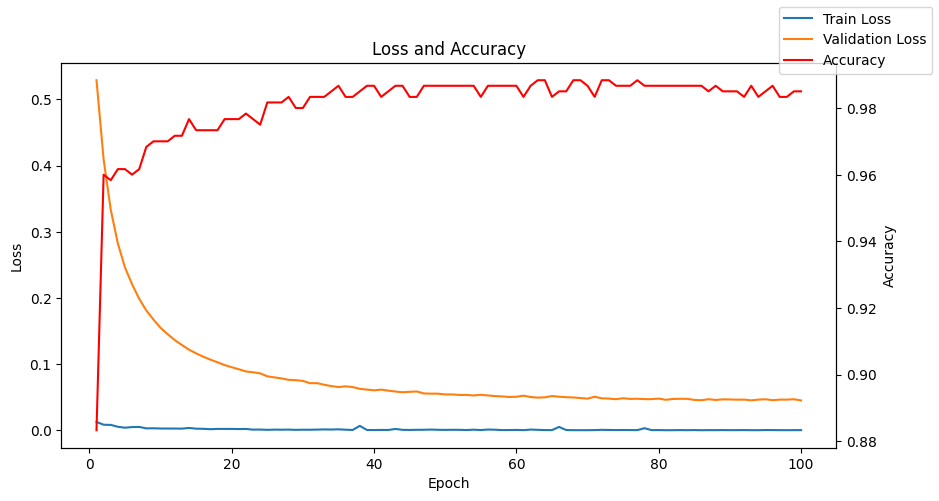

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.plot(epochs_range, validation_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

plt.title('Loss and Accuracy')
fig.legend()
plt.show()

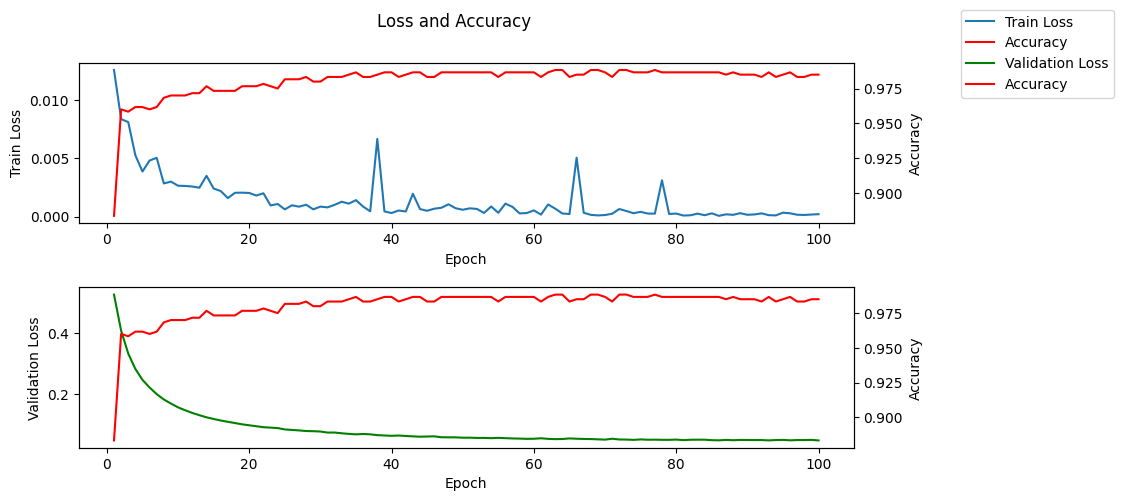

In [8]:
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(epochs_range, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Validation Loss')
ax4.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

# Influences

In [9]:
# Loading data
dogfish_influences = save_objs_dict["dogfish_influences"]
validate_list = save_objs_dict["validate_list"]
rand_list = save_objs_dict["rand_list"]


validate_dict = {
    "validate_accuracies": [],
    "validate_train_losses": [],
    "validate_validation_losses": []
}

rand_dict = {
    "rand_validate_accuracies": [],
    "rand_validate_train_losses": [],
    "rand_validate_validation_losses": []
}

for ckpt_idx, _ in enumerate(checkpoint_labels):
    validate_dict["validate_accuracies"].append(validate_list[ckpt_idx].accuracies)
    validate_dict["validate_train_losses"].append(validate_list[ckpt_idx].train_losses)
    validate_dict["validate_validation_losses"].append(validate_list[ckpt_idx].validation_losses)

    rand_dict["rand_validate_accuracies"].append(rand_list[ckpt_idx].accuracies)
    rand_dict["rand_validate_train_losses"].append(rand_list[ckpt_idx].train_losses)
    rand_dict["rand_validate_validation_losses"].append(rand_list[ckpt_idx].validation_losses)

In [10]:
def top_last_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        ckpt_imgs.append(top_influential_train_data)
    return ckpt_imgs
    
num_data = len(embeds_train_dataset)
x_vals =  list(range(1, num_epochs+1))

In [11]:
checkpoints_filepaths = [os.path.join(dir_ckpt, "V3FC", f"V3FC_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

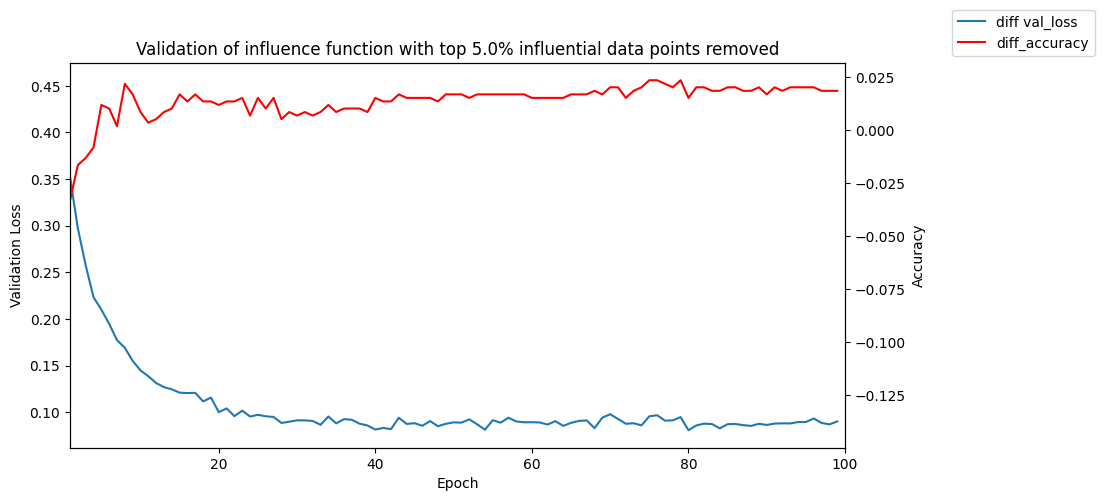

In [12]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_dict["validate_validation_losses"], checkpoint_labels) - concat_ckpt_metrics(rand_dict["rand_validate_train_losses"], checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_dict["rand_validate_accuracies"], checkpoint_labels) - concat_ckpt_metrics(validate_dict["validate_accuracies"], checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {p*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [13]:
def calc_inter_dist(embeds):
    distances = euclidean_distances(embeds, embeds)
    mean_distance = np.mean(distances)
    return mean_distance

def calc_external_dist(inf_embeds, other_embeds):
    distances = euclidean_distances(inf_embeds, other_embeds)
    mean_distance = np.mean(distances)
    return mean_distance

# class balance
def calculate_class_balance(labels):
    unique, counts = np.unique(labels, return_counts=True)
    probabilities = unique / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-8))

def calculate_entropy(embeds):
    hist, _ = np.histogram(embeds.flatten(), bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

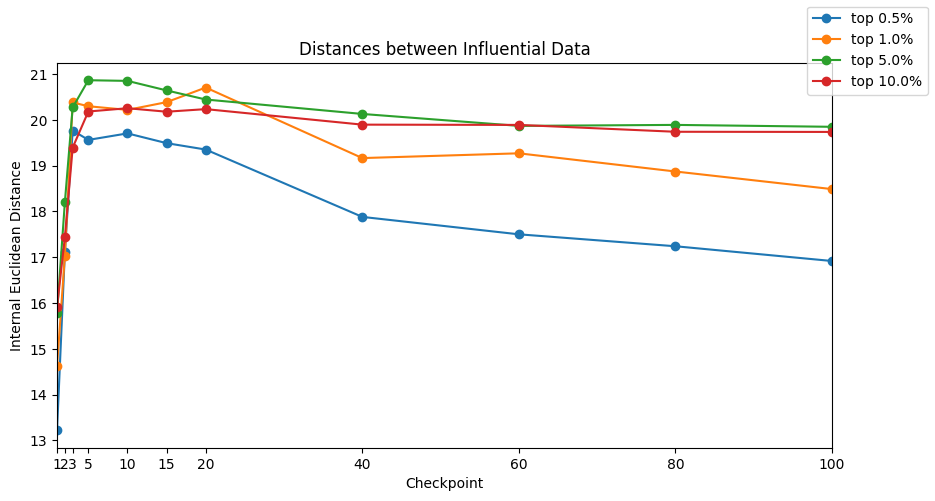

In [14]:
# test selecting 0.5% 1% 5% 10% influential points
num_data = len(embeds_train_dataset)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt_embeds in ckpts_embeds:
        ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
        mean_dist = calc_inter_dist(ckpt_embeds)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
# ax2 = ax1.twinx()
# ax2.set_ylabel("Accuracy")
# ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend()
plt.show()

100%|██████████| 11/11 [00:00<00:00, 32.62it/s]


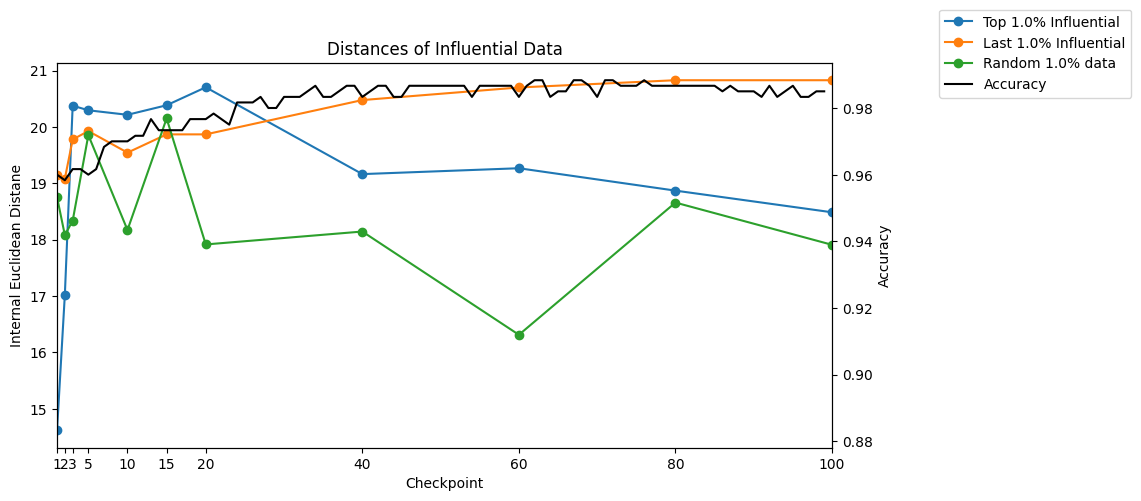

In [15]:
p = 0.01
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, int(p*num_data))
topinf_int_distances = []
for i in range(len(top_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in top_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    topinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, topinf_int_distances, 'o-', label=f"Top {p*100}% Influential")

last_ckpts_embeds = top_last_influences(dogfish_influences, embeds_train_dataset, int(p*num_data), False)
lastinf_int_distances = []
for i in range(len(last_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in last_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    lastinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, lastinf_int_distances, 'o-', label=f"Last {p*100}% Influential")

rand_ckpts_embeds = random_p_data(dogfish_influences, embeds_train_dataset, num_data, p)
rand_int_distances = []
for i in range(len(checkpoint_labels)):
    embeds = np.array([embed[0] for embed in rand_ckpts_embeds[i]])
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*100}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distane")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Distances of Influential Data")
plt.show()

100%|██████████| 11/11 [00:00<00:00, 37.19it/s]


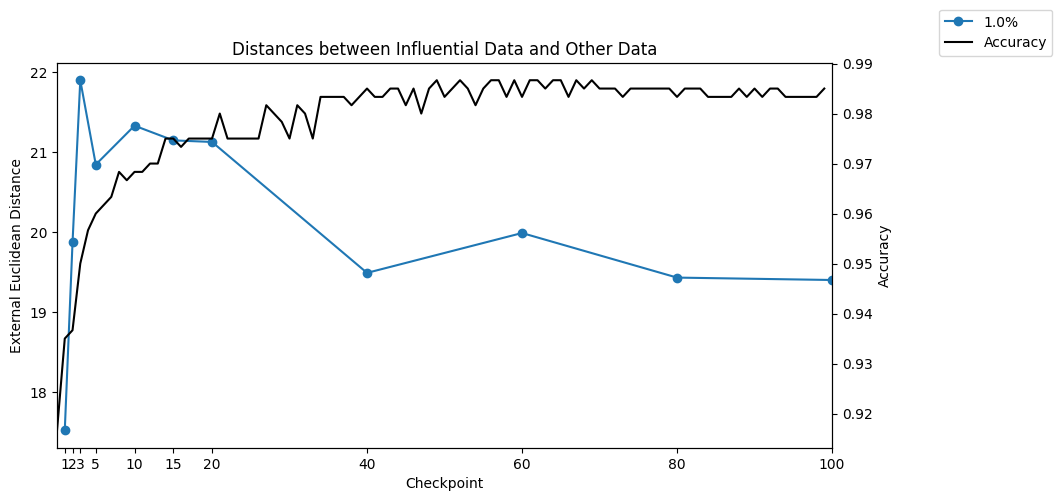

In [16]:
# Euclidean distance from influential points to other points

x_vals =  np.arange(len(checkpoint_labels))
random_embeds = random_p_data(dogfish_influences, embeds_train_dataset, num_data, p)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data and Other Data")
distances = []
for i, ckpt_embeds in enumerate(top_ckpts_embeds):
    inf_embeds = np.array([embed[0] for embed in ckpt_embeds])
    rand_embeds = np.array([embed[0] for embed in random_embeds[i]])
    mean_dist = calc_external_dist(inf_embeds, rand_embeds)
    distances.append(mean_dist)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Z_imgs: (18, 8), volume: 1171845632.0
Z_imgs: (18, 8), volume: 4747496960.0
Z_imgs: (18, 8), volume: 12650313728.0
Z_imgs: (18, 8), volume: 12352836608.0
Z_imgs: (18, 8), volume: 15560374272.0
Z_imgs: (18, 8), volume: 13325087744.0
Z_imgs: (18, 8), volume: 13903667200.0
Z_imgs: (18, 8), volume: 10262827008.0
Z_imgs: (18, 8), volume: 10418778112.0
Z_imgs: (18, 8), volume: 9440251904.0
Z_imgs: (18, 8), volume: 8584054272.0


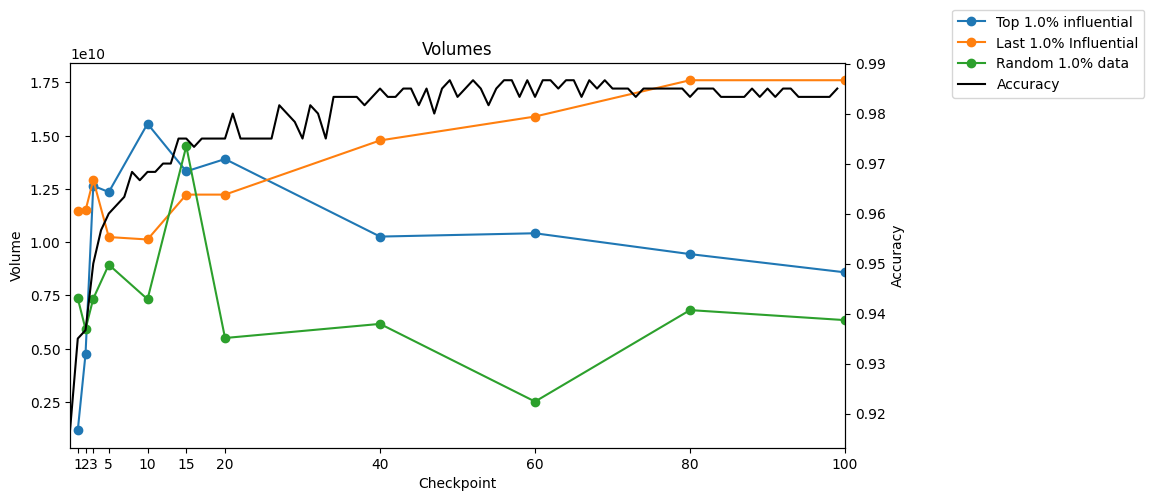

In [17]:
# 0.2 not increase yet; 0.23 ready to increase; 0.252 sharp increase; 0.4 oscillitate, 0.8, 1.0 no change; 0.6 oscillitate; 

from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

topinf_volumes = []
for ckpt_embeds in top_ckpts_embeds:
    # print(ckpt_imgs[0][0].shape)
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(ckpt_embeds, 8)
    Z_imgs = ckpt_embeds @ W.T
    print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    topinf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, topinf_volumes, 'o-', label=f"Top {p*100}% influential")

    
lastinf_volumes = []
for ckpt_embeds in last_ckpts_embeds:
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(ckpt_embeds, 8)
    Z_imgs = ckpt_embeds @ W.T
    # print(f"checkpoint: {ckpt_imgs.shape}")
    lastinf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, lastinf_volumes, 'o-', label=f"Last {p*100}% Influential")

rand_volumes = []
for ckpt_embeds in rand_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])
    W = pca(embeds, 8)
    Z_imgs = embeds @ W.T
    # print(f"checkpoint: {ckpt_imgs.shape}")
    rand_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, rand_volumes, 'o-', label=f"Random {p*100}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Volumes")
plt.show()
# print(len(np.load(DOGFISH_EMB_PATH, mmap_mode='r')["X_train"]))

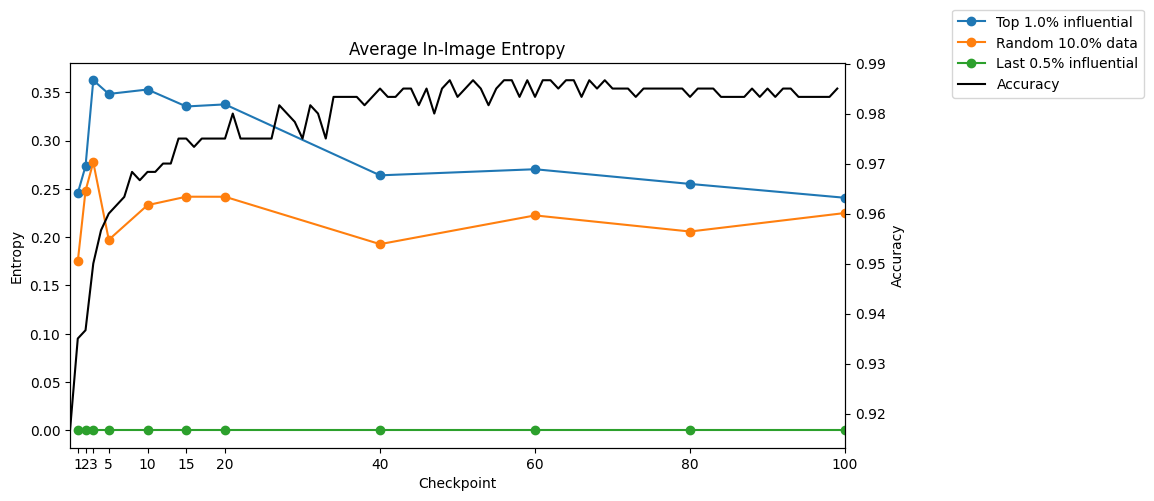

In [18]:
def calculate_entropy(image):
    hist, _ = np.histogram(image[0], bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

entropies = []
for imgs in top_ckpts_embeds:
    ckpt_entropies = [calculate_entropy(img) for img in imgs]
    mean_entropy = np.mean(ckpt_entropies)
    entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, entropies, 'o-', label=f"Top {p*100}% influential")

randimgs_entropies = []
for data in random_embeds:
    ckpt_entropies = [calculate_entropy(img) for img in data]
    mean_entropy = np.mean(ckpt_entropies)
    randimgs_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, randimgs_entropies, 'o-', label=f"Random {p*10*100}% data")


last_inf_entropies = []
for ckpt_imgs in top_last_influences(dogfish_influences, embeds_train_dataset, int(p*num_data), descending=False):
    last_inf_entropy = [calculate_entropy(img[0]) for img in ckpt_imgs]
    mean_entropy = np.mean(last_inf_entropy)
    last_inf_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, last_inf_entropies, 'o-', label="Last 0.5% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
plt.title("Average In-Image Entropy")
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

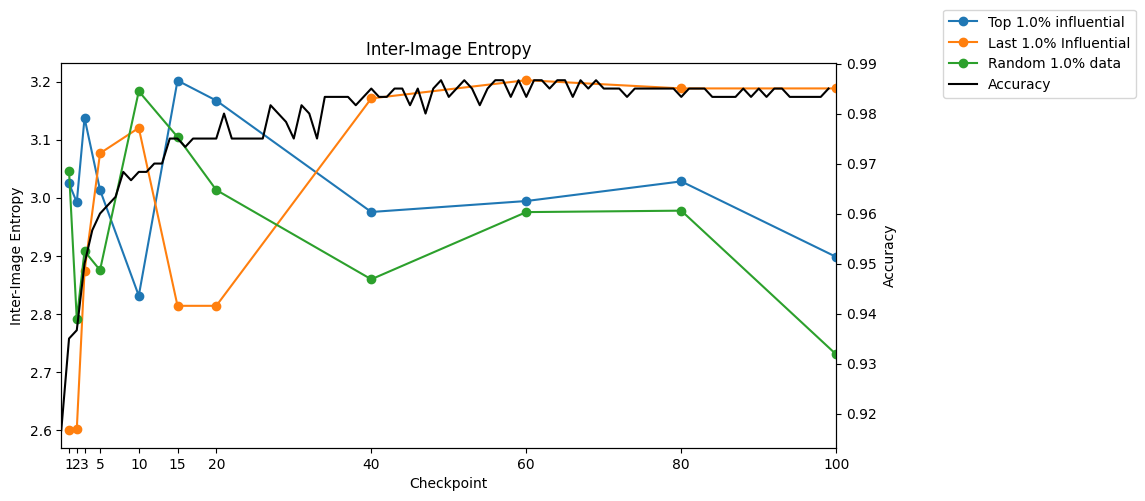

In [19]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

topinf_pw_entropies = []
for embeds in top_ckpts_embeds:
    embeds = np.array([img[0] for img in embeds])
    ckpt_entropies = image_pairwise_entropy(embeds)
    topinf_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, topinf_pw_entropies, 'o-', label=f"Top {p*100}% influential")
    
lastinf_pw_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    ckpt_embeds = np.array([embed[0] for embed in ckpt_embeds])
    pw_entropy = image_pairwise_entropy(ckpt_embeds)
    lastinf_pw_entropies.append(pw_entropy)
ax1.plot(checkpoint_labels, lastinf_pw_entropies, 'o-', label=f"Last {p*100}% Influential")

rand_pw_entropies = []
for ckpt_embeds in rand_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])
    pw_entropy = image_pairwise_entropy(embeds)
    rand_pw_entropies.append(pw_entropy)
ax1.plot(checkpoint_labels, rand_pw_entropies, 'o-', label=f"Random {p*100}% data")

plt.title("Inter-Image Entropy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Inter-Image Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

# Retrain on Top n IP

In [20]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cpu


In [21]:
class V3FC(nn.Module):
    def __init__(self):
        super(V3FC, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(2048, 1),
            nn.Flatten(),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_23416\1076667991.py:8: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ..\torch\csrc\utils\tensor_new.cpp:277.)
  inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)


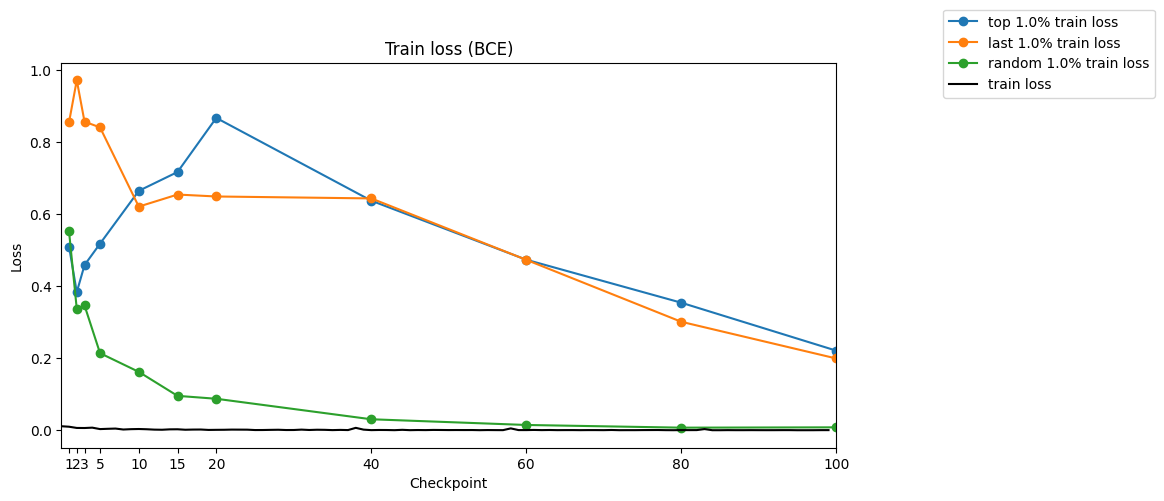

In [22]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    train_losses = [] # BCE loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        optimizer = torch.optim.Adam(V3FC().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        loss_fn = nn.BCELoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/dogfish/dogfish_train_losses.pt")
ax1.plot(train_losses, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

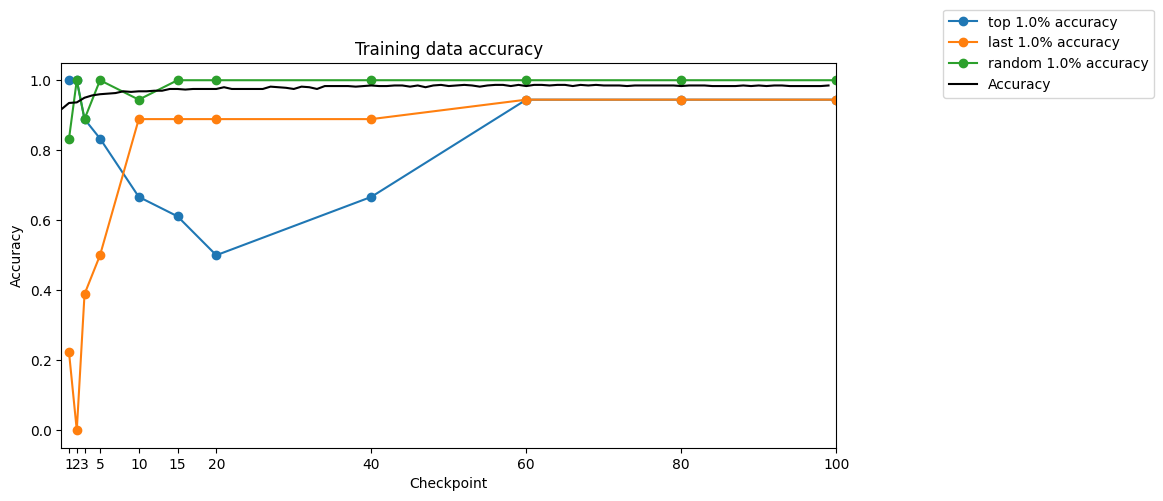

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = (outputs > 0.5).int()
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = (outputs > 0.5).int()
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

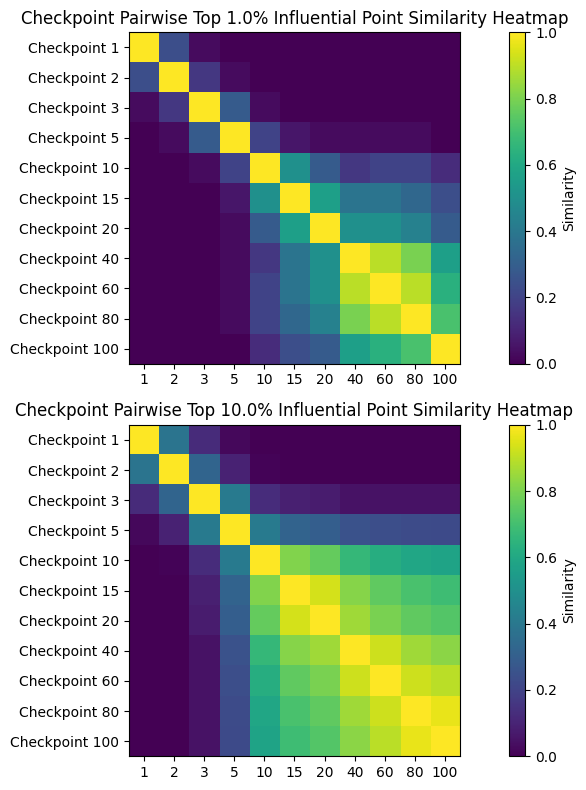

In [25]:
def pairwise_similarity(ckpts_indices):
    similarities = []
    for i in range(len(ckpts_indices)):
        similarity = []
        for j in range(len(ckpts_indices)):
            common = len(set(ckpts_indices[i]).intersection(set(ckpts_indices[j])))
            union = len(set(ckpts_indices[i]).union(set(ckpts_indices[j])))
            similarity.append(common / union)
        similarities.append(similarity)
    return np.array([np.array(sim) for sim in similarities])

def top_last_inf_indices(ckpts_influences, num_per_row, descending=True):
    top_inf_indices = []
    for ckpt_influences in ckpts_influences:
        sorted_influences = torch.argsort(torch.from_numpy(ckpt_influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row].tolist()
        top_inf_indices.append(top_indexes)
    return top_inf_indices
pw_similarities_lowp = pairwise_similarity(top_last_inf_indices(dogfish_influences, int(p*num_data)))
pw_similarities_highp = pairwise_similarity(top_last_inf_indices(dogfish_influences, int(0.1*num_data)))

fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(211)
im1 = ax1.imshow(pw_similarities_lowp, cmap='viridis', interpolation='nearest')
fig.colorbar(im1, ax=ax1, label='Similarity')
ax1.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax1.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax1.set_title(f'Checkpoint Pairwise Top {p*100}% Influential Point Similarity Heatmap')

ax2 = fig.add_subplot(212)
im2 = ax2.imshow(pw_similarities_highp, cmap='viridis', interpolation='nearest')
fig.colorbar(im2, ax=ax2, label='Similarity')
ax2.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax2.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax2.set_title(f'Checkpoint Pairwise Top {0.1*100}% Influential Point Similarity Heatmap')
plt.tight_layout()

plt.show()

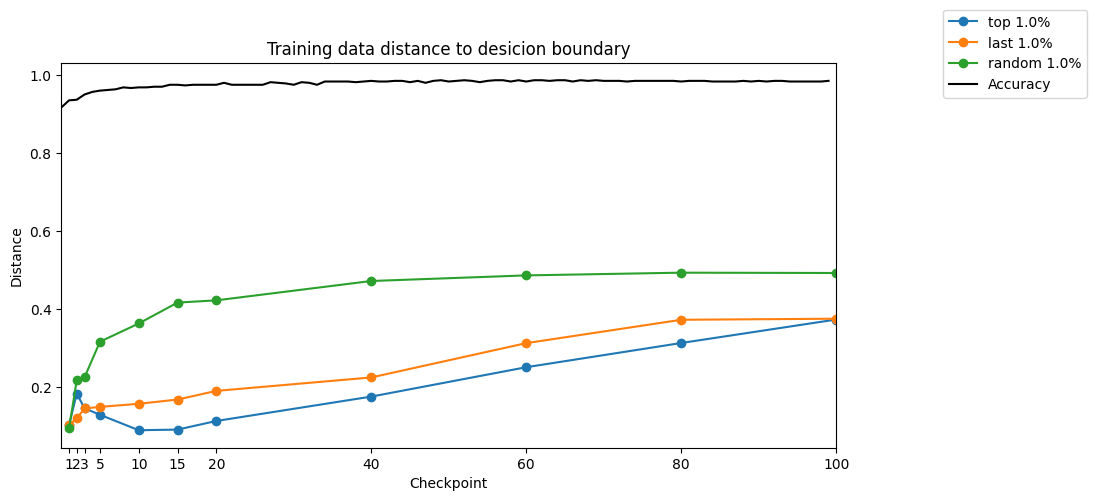

In [28]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, rand_ckpts_embeds]):
    distance_to_dec_boundary = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device)
        model, optimizer, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        distances = torch.mean(torch.abs(outputs - 0.5))
        distance_to_dec_boundary.append(distances.item())
    ax1.plot(checkpoint_labels, distance_to_dec_boundary, 'o-', 
             label=f"{labels[j]} {p*100}%")

plt.title("Training data distance to desicion boundary")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Distance")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Plotting Decision Boundary: 100%|██████████| 11/11 [00:00<00:00, 12.95it/s]


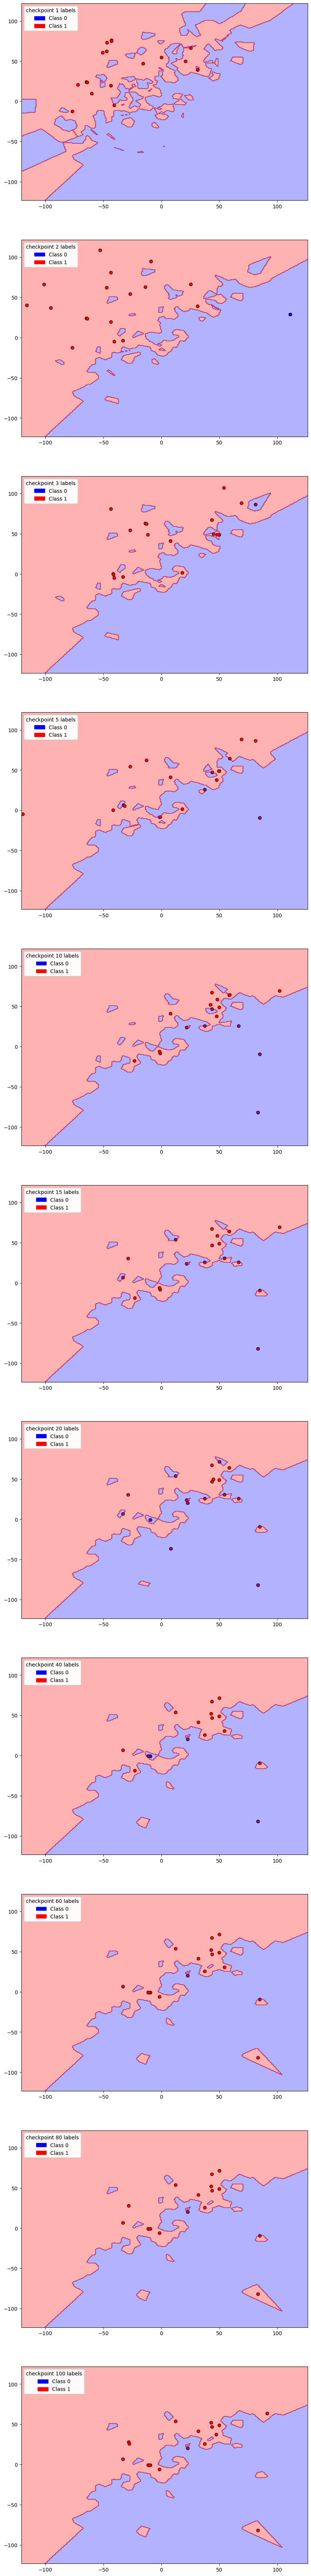

In [33]:
from scipy.interpolate import griddata
import matplotlib.patches as mpatches

ckpts_top_inf_indices = top_last_inf_indices(dogfish_influences, int(p*num_data))
top_inf_data = top_ckpts_embeds[-1]
def tsne_all_dataset(train_dataset):
    all_data_x = np.array([embed[0] for embed in train_dataset])
    all_data_y = np.array([embed[1] for embed in train_dataset], dtype=np.int32)
    tsne = TSNE(n_components=2, random_state=0, perplexity=min(1, len(all_data_x)))
    all_x_2d = tsne.fit_transform(all_data_x)
    return all_x_2d, all_data_y, all_data_x

def plt_decision_boundary(
    top_inf_indices, 
    all_x_2d, 
    all_data_x, all_data_y, 
    ax, i, 
    checkpoints_filepath,
    custom_cmap,
    norm
    ):
    top_inf_x_2d = all_x_2d[top_inf_indices]
    top_inf_y_real = all_data_y[top_inf_indices]
    model, _, _, _ = load_checkpoint(V3FC().to(device), optimizer, checkpoints_filepath)
    all_y_pred = (model(torch.tensor(all_data_x, dtype=torch.float32)) > 0.5).int().numpy().flatten()
    sc = ax.scatter(top_inf_x_2d[:, 0], top_inf_x_2d[:, 1], 
                c=top_inf_y_real, cmap=custom_cmap, norm=norm, edgecolors='k')
    # plt.scatter(all_x_2d[:, 0], all_x_2d[:, 1], c=all_data_y, cmap='viridis', alpha=0.5)

    x_min, x_max = all_x_2d[:, 0].min() - 1, all_x_2d[:, 0].max() + 1
    y_min, y_max = all_x_2d[:, 1].min() - 1, all_x_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                        np.linspace(y_min, y_max, 300))
    grid_pred = griddata(all_x_2d, all_y_pred, (xx, yy), method='nearest')

    ax.contourf(xx, yy, grid_pred, alpha=0.3, cmap=custom_cmap, norm=norm)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    class_patches = [mpatches.Patch(color=custom_cmap(norm(label)), label=f"Class {label}") for label in range(custom_cmap.N)]
    legend_points = ax.legend(*sc.legend_elements(), loc="upper right", title=f"Influential Points")
    legend_background = ax.legend(handles=class_patches, loc="upper left", title=f"checkpoint {checkpoint_labels[i]} labels")
    ax.add_artist(legend_background)
    return ax

all_x_2d, all_data_y, all_data_x = tsne_all_dataset(embeds_train_dataset)
fig, ax = plt.subplots(len(checkpoint_labels), 1, figsize=(10, 90))
custom_cmap = mcolors.ListedColormap(["blue", "red"])
norm = mcolors.Normalize(0, 1)
for i, top_inf_indices in tqdm(enumerate(ckpts_top_inf_indices), desc='Plotting Decision Boundary', total=len(checkpoint_labels)):
    plt_decision_boundary(top_inf_indices, all_x_2d, all_data_x, all_data_y, ax[i], i, checkpoints_filepaths[i], custom_cmap, norm)
# fig.tight_layout()
plt.show()
